In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [17]:
#loading standard MNIST dataset
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

In [18]:
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

In [19]:
images, labels = next(iter(train_loader))
print(images.shape)  
print(labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])


In [ ]:
# my custom CNN architecture
class CustomCNN(nn.Module):
    def __init__(self):
        super(CustomCNN, self).__init__()
        # Conv layer
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        
        # Pooling layer
        self.pool = nn.MaxPool2d(2,2)
        
        # FC
        self.fc1 = nn.Linear(32*3*3, 64)
        self.fc2 = nn.Linear(64, 10)
        
        # ReLU
        self.relu = nn.ReLU()
    
    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)  # flatten
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [ ]:

model = CustomCNN().to(device)
total_params = sum(p.numel() for p in model.parameters())
print("Total trainable parameters:", total_params)

Total trainable parameters: 25034


In [22]:
# here learning starts
criterion = nn.CrossEntropyLoss()         
optimizer = optim.Adam(model.parameters(), lr=0.001) 

num_epochs = 10  
train_losses, train_acc = [], []
val_losses, val_acc = [], []

In [23]:
for epoch in range(num_epochs):
    model.train()  
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()       
        outputs = model(images)     # Forward pass
        loss = criterion(outputs, labels)  # Compute loss
        loss.backward()             # Backpropagate
        optimizer.step()            # Update weights
        
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    train_losses.append(running_loss / total)
    train_acc.append(correct / total)
    
    # Validation
    model.eval()  
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():  
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    val_losses.append(val_loss / val_total)
    val_acc.append(val_correct / val_total)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] "
          f"Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_acc[-1]:.4f} "
          f"Val Loss: {val_losses[-1]:.4f}, Val Acc: {val_acc[-1]:.4f}")

Epoch [1/10] Train Loss: 0.3608, Train Acc: 0.8879 Val Loss: 0.1045, Val Acc: 0.9653
Epoch [2/10] Train Loss: 0.0995, Train Acc: 0.9695 Val Loss: 0.0630, Val Acc: 0.9797
Epoch [3/10] Train Loss: 0.0729, Train Acc: 0.9766 Val Loss: 0.0504, Val Acc: 0.9845
Epoch [4/10] Train Loss: 0.0575, Train Acc: 0.9818 Val Loss: 0.0466, Val Acc: 0.9862
Epoch [5/10] Train Loss: 0.0468, Train Acc: 0.9853 Val Loss: 0.0427, Val Acc: 0.9863
Epoch [6/10] Train Loss: 0.0401, Train Acc: 0.9872 Val Loss: 0.0444, Val Acc: 0.9863
Epoch [7/10] Train Loss: 0.0365, Train Acc: 0.9883 Val Loss: 0.0484, Val Acc: 0.9856
Epoch [8/10] Train Loss: 0.0320, Train Acc: 0.9895 Val Loss: 0.0414, Val Acc: 0.9872
Epoch [9/10] Train Loss: 0.0288, Train Acc: 0.9910 Val Loss: 0.0434, Val Acc: 0.9861
Epoch [10/10] Train Loss: 0.0257, Train Acc: 0.9917 Val Loss: 0.0299, Val Acc: 0.9904


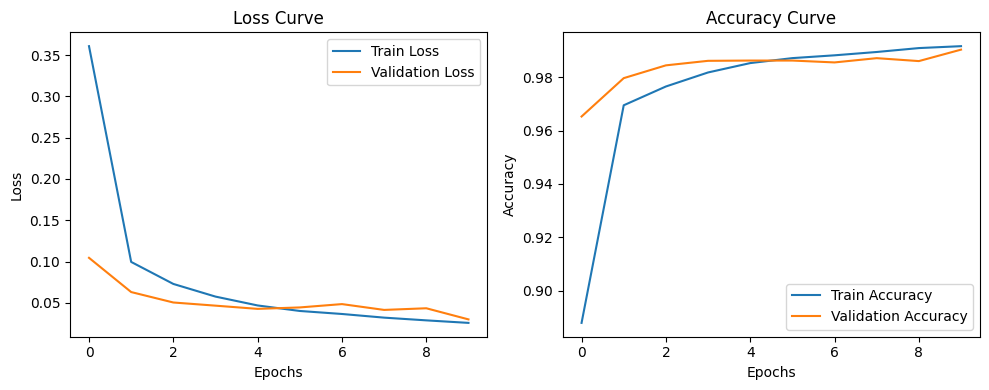

In [24]:
# Loss plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curve')

# Accuracy plot
plt.subplot(1,2,2)
plt.plot(train_acc, label='Train Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy Curve')

plt.tight_layout()
plt.savefig("../results/mnist_training_curves.png")
plt.show()

In [25]:
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = test_correct / test_total
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Accuracy: 0.9904


In [26]:
torch.save(model.state_dict(), "../models/mnist_cnn.pth")

####  Analysis: Examine your loss curves. Did your model overfit, underfit, or generalize well? Justify your answer by referencing the gap (or lack thereof) between the training and validation curves.

From the loss and accuracy curves, the model generalizes well.

We can see that both the training loss and validation loss are decreasing over the epochs, which shows that the model is learning properly. Also, the training accuracy and validation accuracy are both increasing and remain very close to each other throughout training.

There is no large gap between training and validation performance. For example, in the final epochs, training accuracy is around 99.17% and validation accuracy is around 99.04%, which is very close. This means the model is not memorizing the training data.

If the model was overfitting, we would see training accuracy very high and validation accuracy much lower, but that is not happening here. Similarly, it is not underfitting because both accuracies are high.

So overall, the model is generalizing well and performing consistently on both training and validation data maybe beacause we followed the constraint of > 50k.

#### Analysis: Extract the weights of the filters from your first convolutional layer. Plot them as images. Can you visually identify any rudimentary edge or texture detection occurring? Briefly explain what these filters seem to be capturing.


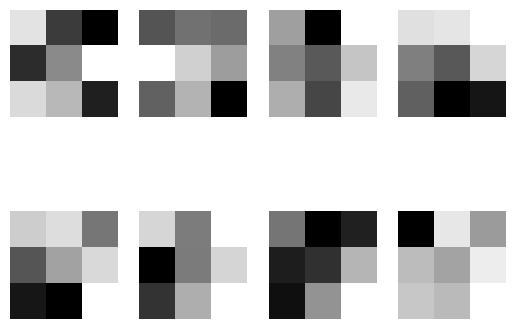

In [30]:
filters = model.conv1.weight.data.cpu().numpy()

for i in range(filters.shape[0]):
    plt.subplot(2,4,i+1)
    plt.imshow(filters[i][0], cmap='gray')
    plt.axis('off')

After visualizing the filters from the first conv layer, we can see that different filters have learned different patterns. Some filters appear to highlight edges, especially where there are transitions between light and dark regions. A few filters seem to capture vertical or horizontal edge-like structures, while others look more like general intensity patterns. Some filters may look noisy, which is normal in early stages of learning. Overall, these filters are capturing basic low-level features such as edges and simple textures.